# Desain eksperimen: klasifikasi mutu kopi arabika (ViT) — RAK faktorial 2×2×4

**Faktor:** sumber pre-training (ImageNet torchvision, HuggingFace) × patch size (16, 32) × jumlah data latih (16/14/10/8 sampel per kelas ≈ 80/70/50/40%)  
**Blok:** replikasi 1–10 (tiap blok = pengacakan ulang sampel fisik ke train/test; test set dikunci 4 sampel/kelas). Total 16 × 10 = 160 run.  
**Respon utama:** akurasi test (240 citra dari 24 sampel). **Respon sekunder:** akurasi pada 60 citra prediksi eksternal.  
**Dikontrol (identik untuk semua perlakuan):** head Dropout(0,1)+Linear, AdamW lr 1e-3 wd 0,03, batch 10, 90 epoch, tanpa augmentasi.  
**Urutan:** Langkah 1 (sekali, GPU) → Langkah 2 (160 run, CPU) → Langkah 3 (ANOVA).

Syarat Kaggle: Internet ON (unduh bobot torchvision dan HuggingFace), dataset `arabica-beans` dan `prediction-arabica-class` ditambahkan sebagai input.

## Langkah 1 — Ekstraksi fitur 4 backbone (frozen), sekali jalan
Aktifkan GPU untuk langkah ini saja.

In [3]:
"""
01_extract_features.py
----------------------
Ekstraksi fitur 768-dim (token [CLS]) dari 4 backbone ViT-Base yang di-freeze:
  imgnet16 / imgnet32 : torchvision (ViT_B_16 / ViT_B_32 Weights.DEFAULT, input 224)
  hf16     / hf32     : HuggingFace google/vit-base-patch16-224 / google/vit-base-patch32-384
Dijalankan SEKALI. Hasilnya dipakai ulang di 02_run_replicates.py.

Kenapa boleh di-cache (sudah dicek dari notebook skripsi):
  - backbone di-freeze, hanya head yang dilatih
  - transform deterministik (TANPA augmentasi acak). Catatan: notebook HF lama memakai
    RandomHorizontalFlip, dan transform itu ikut terpakai di test set. Di sini flip dibuang.
  - dropout backbone = 0 (torchvision default 0.0; HF config 0.0, dicek lewat assert)

Semua 1200 citra = isi folder 80-20/train + 80-20/test. Split asli skripsi tidak dipakai;
split dibuat ulang di level SAMPEL di skrip 02.
"""
import os
import re
from collections import Counter, defaultdict

import numpy as np
import torch
import torchvision
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms

# ====== KONFIGURASI (sesuaikan path Kaggle) ======
ROOT = "/kaggle/input/datasets/zaafirrahman/arabica-beans/arabica_beans/80-20"
PRED_ROOT = "/kaggle/input/datasets/zaafirrahman/predict-arabica-beans/Citra Biji Kopi (Prediksi)"
OUT_DIR = "/kaggle/working/features"
BATCH = 32
TV_BACKBONES = {
    "imgnet16": (torchvision.models.vit_b_16, torchvision.models.ViT_B_16_Weights.DEFAULT),
    "imgnet32": (torchvision.models.vit_b_32, torchvision.models.ViT_B_32_Weights.DEFAULT),
}
HF_BACKBONES = {
    "hf16": "google/vit-base-patch16-224",
    "hf32": "google/vit-base-patch32-384",
}
# "native" = mean/std milik model HF (0.5/0.5), "imagenet" = 0.485.. seperti notebook skripsi
HF_NORM = "native"
# Pola nama file contoh: 1T-01.jpg -> mutu 1, sampel "T", foto ke-01
FNAME = re.compile(r"^(\d)([A-Za-z]+)-(\d+)\.(jpg|jpeg|png)$", re.IGNORECASE)
# =================================================

os.makedirs(OUT_DIR, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"


def collect_images():
    """Gabungkan train+test dari 80-20, parse ID sampel dari nama file, lalu validasi."""
    items = []
    for split in ("train", "test"):
        ds = datasets.ImageFolder(os.path.join(ROOT, split))
        assert ds.classes == [f"mutu{i}" for i in range(1, 7)], ds.classes
        items += ds.samples  # (path, label)
    items.sort(key=lambda t: t[0])  # urutan deterministik

    paths, labels, samples = [], [], []
    bad = []
    for p, y in items:
        m = FNAME.match(os.path.basename(p))
        if not m or int(m.group(1)) != y + 1:
            bad.append(os.path.basename(p))
            continue
        paths.append(p)
        labels.append(y)
        samples.append(f"{m.group(1)}{m.group(2).upper()}")  # misal "1T"
    if bad:
        raise ValueError(
            f"{len(bad)} nama file tidak cocok pola <mutu><huruf>-<nomor>.jpg, contoh: {bad[:5]}. "
            "Kabari aku format nama filenya supaya regex disesuaikan."
        )

    # ---- validasi struktur: harapannya 6 kelas x 20 sampel x 10 foto = 1200 ----
    per_class = defaultdict(set)
    for y, s in zip(labels, samples):
        per_class[y].add(s)
    photos = Counter(samples)
    print(f"Total citra       : {len(paths)} (harapan 1200)")
    print(f"Duplikat nama file: {len(paths) - len(set(map(os.path.basename, paths)))}")
    print("Sampel per kelas  :", {f"mutu{c+1}": len(v) for c, v in sorted(per_class.items())})
    print("Foto per sampel   :", dict(Counter(photos.values())), "(harapan {10: 120})")
    return paths, np.array(labels), np.array(samples)


def collect_pred():
    """Citra prediksi (set eksternal). Return (paths, y) atau None jika folder tidak ada."""
    if not os.path.isdir(PRED_ROOT):
        print(f"PRED_ROOT tidak ditemukan ({PRED_ROOT}); set prediksi dilewati")
        return None
    ds = datasets.ImageFolder(PRED_ROOT)
    assert ds.classes == [f"mutu{i}" for i in range(1, 7)], ds.classes
    items = sorted(ds.samples, key=lambda t: t[0])
    print(f"Citra prediksi: {len(items)} (harapan 60)")
    return [p for p, _ in items], np.array([y for _, y in items])


class PathDataset(Dataset):
    def __init__(self, paths, tf):
        self.paths, self.tf = paths, tf

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB"))


@torch.no_grad()
def embed(fwd, tf, paths):
    """fwd: fungsi batch-gambar -> fitur (B, 768)."""
    dl = DataLoader(PathDataset(paths, tf), batch_size=BATCH, shuffle=False, num_workers=2)
    out = []
    for i, xb in enumerate(dl):
        out.append(fwd(xb.to(device)).cpu().numpy().astype(np.float32))
        if i % 10 == 0:
            print(f"  batch {i+1}/{len(dl)}")
    return np.concatenate(out)


def save(name, tf, fwd, paths, y, samples, pred):
    print(f"\n[{name}] transform:\n{tf}")
    X = embed(fwd, tf, paths)
    np.savez_compressed(os.path.join(OUT_DIR, f"{name}.npz"),
                        X=X, y=y, sample=samples, path=np.array(paths))
    if pred is not None:  # transform SAMA dengan training (bukan Resize 224 langsung seperti notebook lama)
        Xp = embed(fwd, tf, pred[0])
        np.savez_compressed(os.path.join(OUT_DIR, f"{name}_pred.npz"),
                            X=Xp, y=pred[1], path=np.array(pred[0]))
    with open(os.path.join(OUT_DIR, f"{name}_transform.txt"), "w") as f:
        f.write(repr(tf))
    print(f"[{name}] fitur {X.shape} tersimpan")


def extract_tv(name, ctor, weights, paths, y, samples, pred):
    model = ctor(weights=weights)
    model.heads = nn.Identity()  # keluaran = token [CLS] 768-dim setelah LayerNorm akhir
    model.eval().to(device)
    save(name, weights.transforms(), model, paths, y, samples, pred)


def extract_hf(name, repo, paths, y, samples, pred):
    from transformers import AutoImageProcessor, AutoModelForImageClassification
    proc = AutoImageProcessor.from_pretrained(repo)
    size = proc.size.get("height") or proc.size.get("shortest_edge")
    mean, std = (proc.image_mean, proc.image_std) if HF_NORM == "native" \
        else ([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    tf = transforms.Compose([                      # tanpa RandomHorizontalFlip
        transforms.Resize((size, size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])
    model = AutoModelForImageClassification.from_pretrained(repo).eval().to(device)
    assert model.config.hidden_dropout_prob == 0 and model.config.attention_probs_dropout_prob == 0
    base = model.base_model  # ViTModel; last_hidden_state sudah melewati LayerNorm akhir

    def fwd(xb):
        return base(pixel_values=xb).last_hidden_state[:, 0]  # token [CLS], input classifier HF

    save(name, tf, fwd, paths, y, samples, pred)


if __name__ == "__main__":
    paths, y, samples = collect_images()
    pred = collect_pred()
    for name, (ctor, w) in TV_BACKBONES.items():
        extract_tv(name, ctor, w, paths, y, samples, pred)
    for name, repo in HF_BACKBONES.items():
        extract_hf(name, repo, paths, y, samples, pred)


Total citra       : 1200 (harapan 1200)
Duplikat nama file: 0
Sampel per kelas  : {'mutu1': 20, 'mutu2': 20, 'mutu3': 20, 'mutu4': 20, 'mutu5': 20, 'mutu6': 20}
Foto per sampel   : {10: 120} (harapan {10: 120})
Citra prediksi: 60 (harapan 60)
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 225MB/s] 



[imgnet16] transform:
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
  batch 1/38
  batch 11/38
  batch 21/38
  batch 31/38
  batch 1/2
[imgnet16] fitur (1200, 768) tersimpan
Downloading: "https://download.pytorch.org/models/vit_b_32-d86f8d99.pth" to /root/.cache/torch/hub/checkpoints/vit_b_32-d86f8d99.pth


100%|██████████| 337M/337M [00:01<00:00, 231MB/s] 



[imgnet32] transform:
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
  batch 1/38
  batch 11/38
  batch 21/38
  batch 31/38
  batch 1/2
[imgnet32] fitur (1200, 768) tersimpan


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

... (7 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]


[hf32] transform:
Compose(
    Resize(size=(384, 384), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
)
  batch 1/38
  batch 11/38
  batch 21/38
  batch 31/38
  batch 1/2
[hf32] fitur (1200, 768) tersimpan


## Langkah 2 — Replikasi: latih head di atas fitur tersimpan
Resume otomatis: kalau sesi putus, jalankan ulang sel ini dan run yang sudah selesai dilewati. Perhatikan kolom `loss_drop_last10` (≈0 berarti sudah konvergen).

In [4]:
"""
02_run_replicates.py
--------------------
Desain: faktorial 2 x 2 x 4 dalam Rancangan Acak Kelompok (RAK).
  Faktor A : sumber pre-training (ImageNet torchvision, HuggingFace)
  Faktor B : patch size (16, 32)
  Faktor C : jumlah data latih (sampel per kelas) -> 16, 14, 10, 8  (setara 80/70/50/40 % dari 20 sampel)
  Blok     : replikasi r = 1..R. Tiap blok = satu pengacakan sampel fisik ke train/test.
             Di dalam satu blok, SEMUA perlakuan memakai test set yang sama (4 sampel/kelas = 240 citra),
             dan train set bersarang (8 sampel pertama termasuk di 10, 14, 16).
  Respon   : akurasi test (epoch terakhir, bukan epoch terbaik, supaya test set tidak ikut "memilih" model)
             + pred_acc = akurasi pada 60 citra prediksi eksternal (respon sekunder)

Split dilakukan di level SAMPEL FISIK (bukan per citra) supaya foto dari sampel yang sama
tidak bocor antara train dan test.

Protokol training head IDENTIK untuk semua perlakuan (supaya faktor A tidak tercampur dengan
perbedaan epoch/lr/dropout; di skripsi HF: 50 epoch, lr 1e-4, tanpa dropout head, ada flip):
  Dropout(0.1) + Linear(768->6), AdamW lr=1e-3 wd=3e-2, batch 10, 90 epoch, CrossEntropy.
Konvergensi dicatat per run (loss_final, loss_drop_last10).
"""
import os

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import f1_score
from torch import nn

# ====== KONFIGURASI ======
FEAT_DIR = "/kaggle/working/features"
OUT_CSV = "/kaggle/working/results.csv"
SPLIT_CSV = "/kaggle/working/splits.csv"
BACKBONES = {                                  # nama file fitur -> (sumber, patch size)
    "imgnet16": ("ImageNet", 16), "imgnet32": ("ImageNet", 32),
    "hf16": ("HF", 16), "hf32": ("HF", 32),
}
TRAIN_N = [16, 14, 10, 8]                      # sampel per kelas untuk training
N_TEST = 4                                     # sampel per kelas, dikunci per blok
R = 10                                         # jumlah blok/replikasi
BASE_SEED = 2024
EPOCHS, BATCH, LR, WD, DROP = 90, 10, 1e-3, 3e-2, 0.1
DEVICE = "cpu"   # head sekecil ini lebih cepat di CPU daripada GPU (overhead launch kernel)
# =========================


def load(name):
    d = np.load(os.path.join(FEAT_DIR, f"{name}.npz"), allow_pickle=False)
    return d["X"], d["y"], d["sample"]


def make_block_split(y, sample, rng):
    """Acak urutan sampel di tiap kelas. Return {kelas: array id sampel terurut acak}."""
    order = {}
    for c in np.unique(y):
        ids = np.unique(sample[y == c])
        order[c] = rng.permutation(ids)
    return order


def select(order, k_train):
    """Ambil id sampel train (k pertama dari pool) dan test (N_TEST terakhir) per kelas."""
    tr, te = [], []
    for c, ids in order.items():
        pool = ids[: len(ids) - N_TEST]
        assert k_train <= len(pool), f"k_train={k_train} > pool={len(pool)}"
        tr += list(pool[:k_train])
        te += list(ids[len(ids) - N_TEST:])
    return np.array(tr), np.array(te)


def train_head(Xtr, ytr, Xte, yte, seed, Xpr=None, ypr=None):
    torch.manual_seed(seed)
    head = nn.Sequential(nn.Dropout(DROP), nn.Linear(768, 6)).to(DEVICE)
    opt = torch.optim.AdamW(head.parameters(), lr=LR, weight_decay=WD)
    g = torch.Generator().manual_seed(seed)
    n = len(Xtr)
    losses = []
    for _ in range(EPOCHS):
        head.train()
        perm = torch.randperm(n, generator=g)
        ep_loss = 0.0
        for i in range(0, n, BATCH):
            idx = perm[i:i + BATCH]
            opt.zero_grad()
            loss = F.cross_entropy(head(Xtr[idx]), ytr[idx])
            loss.backward()
            opt.step()
            ep_loss += loss.item() * len(idx)
        losses.append(ep_loss / n)
    head.eval()
    with torch.no_grad():
        p_tr = head(Xtr).argmax(1).numpy()
        p_te = head(Xte).argmax(1).numpy()
        p_pr = head(Xpr).argmax(1).numpy() if Xpr is not None else None
    ytr_n, yte_n = ytr.numpy(), yte.numpy()
    out = {
        "train_acc": float((p_tr == ytr_n).mean()),
        "test_acc": float((p_te == yte_n).mean()),
        "test_macro_f1": float(f1_score(yte_n, p_te, average="macro")),
        "loss_final": losses[-1],
        "loss_drop_last10": (losses[-10] - losses[-1]) / losses[-10],  # ~0 = sudah konvergen
    }
    if p_pr is not None:  # set prediksi eksternal (60 citra, sampel terpisah dari 120 sampel)
        out["pred_acc"] = float((p_pr == ypr.numpy()).mean())
    return out


def main():
    feats = {b: load(b) for b in BACKBONES}
    preds = {}
    for b in BACKBONES:
        fp = os.path.join(FEAT_DIR, f"{b}_pred.npz")
        if os.path.exists(fp):
            d = np.load(fp, allow_pickle=False)
            preds[b] = (torch.from_numpy(d["X"]), torch.from_numpy(d["y"]).long())
    # semua backbone harus punya urutan citra & ID sampel yang sama
    ref = next(iter(feats.values()))
    for b, (_, y, s) in feats.items():
        assert np.array_equal(y, ref[1]) and np.array_equal(s, ref[2]), f"urutan {b} beda"
    y_all, s_all = ref[1], ref[2]

    done = set()
    if os.path.exists(OUT_CSV):
        prev = pd.read_csv(OUT_CSV)
        done = set(zip(prev.block, prev.source, prev.patch, prev.train_n))
        print(f"Lanjut dari {len(prev)} run yang sudah ada")
    split_rows = []

    for r in range(1, R + 1):
        rng = np.random.default_rng(BASE_SEED + r)
        order = make_block_split(y_all, s_all, rng)

        # catat split blok ini (untuk audit/laporan)
        _, te_ids = select(order, TRAIN_N[0])
        for c, ids in order.items():
            for rank, sid in enumerate(ids):
                split_rows.append({"block": r, "class": f"mutu{c+1}", "sample": sid,
                                   "rank": rank, "in_test": sid in set(te_ids)})

        # randomisasi urutan perlakuan di dalam blok
        treatments = [(b, k) for b in BACKBONES for k in TRAIN_N]  # 4 backbone x 4 level = 16
        treatments = [treatments[i] for i in rng.permutation(len(treatments))]

        for pos, (b, k) in enumerate(treatments, start=1):
            source, patch = BACKBONES[b]
            if (r, source, patch, k) in done:
                continue
            tr_ids, te_ids = select(order, k)
            X, _, _ = feats[b]
            m_tr, m_te = np.isin(s_all, tr_ids), np.isin(s_all, te_ids)
            assert not (m_tr & m_te).any(), "kebocoran: ada sampel di train dan test"
            seed = BASE_SEED * 1000 + r * 100 + pos
            Xpr, ypr = preds.get(b, (None, None))
            res = train_head(
                torch.from_numpy(X[m_tr]), torch.from_numpy(y_all[m_tr]).long(),
                torch.from_numpy(X[m_te]), torch.from_numpy(y_all[m_te]).long(), seed, Xpr, ypr,
            )
            row = {"block": r, "source": source, "patch": patch, "train_n": k, "run_order": pos, "seed": seed,
                   "n_train_img": int(m_tr.sum()), "n_test_img": int(m_te.sum()), **res}
            pd.DataFrame([row]).to_csv(OUT_CSV, mode="a", index=False, header=not os.path.exists(OUT_CSV))
            print(f"blok {r:2d} | {source:8s} patch {patch} | train_n {k:2d} | test_acc {res['test_acc']:.4f} "
                  f"| loss_drop_last10 {res['loss_drop_last10']:.3f}")

    pd.DataFrame(split_rows).to_csv(SPLIT_CSV, index=False)
    print("Selesai ->", OUT_CSV)


if __name__ == "__main__":
    main()


blok  1 | ImageNet patch 32 | train_n 16 | test_acc 0.8208 | loss_drop_last10 0.003
blok  1 | ImageNet patch 16 | train_n 16 | test_acc 0.7500 | loss_drop_last10 -0.020
blok  1 | ImageNet patch 32 | train_n 14 | test_acc 0.7708 | loss_drop_last10 0.073
blok  1 | ImageNet patch 32 | train_n 10 | test_acc 0.7333 | loss_drop_last10 0.098
blok  1 | HF       patch 32 | train_n 14 | test_acc 0.8083 | loss_drop_last10 -0.103
blok  1 | HF       patch 16 | train_n 16 | test_acc 0.8083 | loss_drop_last10 0.111
blok  1 | HF       patch 32 | train_n 10 | test_acc 0.7833 | loss_drop_last10 0.073
blok  1 | ImageNet patch 32 | train_n  8 | test_acc 0.7208 | loss_drop_last10 0.051
blok  1 | ImageNet patch 16 | train_n 10 | test_acc 0.7667 | loss_drop_last10 0.159
blok  1 | HF       patch 16 | train_n 10 | test_acc 0.7292 | loss_drop_last10 0.107
blok  1 | HF       patch 16 | train_n  8 | test_acc 0.7833 | loss_drop_last10 0.069
blok  1 | ImageNet patch 16 | train_n  8 | test_acc 0.7583 | loss_drop_las

## Langkah 3 — ANOVA RAK faktorial, uji asumsi, post hoc
Untuk respon sekunder ganti `RESP = "pred_acc"`.

In [5]:
import os
os.environ["RESULTS_CSV"] = "/kaggle/working/results.csv"
os.environ["ANOVA_OUT"] = "/kaggle/working/anova_out"

"""
03_anova.py
-----------
Analisis RAK faktorial 2 (sumber pre-training) x 2 (patch) x 4 (jumlah data latih), blok = replikasi.
  model : y ~ C(block) + C(source) * C(patch) * C(train_n)   (kolom source dipakai jika ada)
  uji   : ANOVA, partial eta-squared, Shapiro-Wilk, Levene (Brown-Forsythe), Durbin-Watson,
          plot residual, Tukey HSD
Jalankan lokal atau di Kaggle:  RESULTS_CSV=results.csv python 03_anova.py
"""
import os

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.stattools import durbin_watson

CSV = os.environ.get("RESULTS_CSV", "results.csv")
OUT = os.environ.get("ANOVA_OUT", "anova_out")
RESP = "test_acc"       # atau "test_macro_f1"
ASIN_SQRT = False       # True jika asumsi gagal (respon proporsi) -> transformasi arcsin(sqrt(y))
ALPHA = 0.05

os.makedirs(OUT, exist_ok=True)
df = pd.read_csv(CSV)
df["y"] = np.arcsin(np.sqrt(df[RESP])) if ASIN_SQRT else df[RESP]
df["block"] = df["block"].astype(str)
df["patch"] = df["patch"].astype(str)
df["train_n"] = df["train_n"].astype(str)
HAS_SRC = "source" in df.columns and df["source"].nunique() > 1
FACTORS = (["source"] if HAS_SRC else []) + ["patch", "train_n"]
df["cell"] = df[FACTORS].agg("|".join, axis=1)

log = []
def say(s=""):
    print(s)
    log.append(str(s))

say(f"Respon: {RESP}{' (arcsin-sqrt)' if ASIN_SQRT else ''} | n = {len(df)} run | blok = {df.block.nunique()}")
say(f"Run per sel (harus seimbang): {sorted(df.groupby('cell').size().unique())}\n")

# ---- deskriptif ----
desc = df.groupby(FACTORS)[RESP].agg(["count", "mean", "std"]).round(4)
say("Rata-rata per sel:\n" + desc.to_string() + "\n")

# ---- ANOVA ----
formula = "y ~ C(block) + " + " * ".join(f"C({f})" for f in FACTORS)
say(f"Model: {formula}")
model = smf.ols(formula, data=df).fit()
tab = anova_lm(model, typ=2)
tab["partial_eta_sq"] = tab["sum_sq"] / (tab["sum_sq"] + tab.loc["Residual", "sum_sq"])
tab.loc["Residual", "partial_eta_sq"] = np.nan
say("ANOVA (Type II; desain seimbang sehingga sama dengan Type I/III):\n" + tab.round(5).to_string() + "\n")

# ---- uji asumsi ----
resid = model.resid
sw = stats.shapiro(resid)
lv = stats.levene(*[g["y"].values for _, g in df.groupby("cell")], center="median")
df_sorted = df.assign(resid=resid).sort_values(["block", "run_order"])
dw = durbin_watson(df_sorted["resid"].values)
say("Uji asumsi:")
say(f"  Normalitas residual (Shapiro-Wilk): W={sw.statistic:.4f}, p={sw.pvalue:.4f} -> {'OK' if sw.pvalue > ALPHA else 'GAGAL'}")
say(f"  Homogenitas varians (Levene median): F={lv.statistic:.4f}, p={lv.pvalue:.4f} -> {'OK' if lv.pvalue > ALPHA else 'GAGAL'}")
say(f"  Independensi (Durbin-Watson): DW={dw:.3f} (sekitar 2 = tidak ada autokorelasi)\n")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(model.fittedvalues, resid, s=12); ax[0].axhline(0, c="k", lw=.8)
ax[0].set(xlabel="Fitted", ylabel="Residual", title="Residual vs fitted")
sm.qqplot(resid, line="s", ax=ax[1]); ax[1].set_title("Q-Q plot residual")
ax[2].plot(df_sorted["resid"].values, marker="o", ms=3, lw=.6); ax[2].axhline(0, c="k", lw=.8)
ax[2].set(xlabel="Urutan run", ylabel="Residual", title="Residual vs urutan run")
plt.tight_layout(); plt.savefig(f"{OUT}/residual_plots.png", dpi=150); plt.close()

# ---- interaction plot ----
fig, ax = plt.subplots(figsize=(6, 4))
line_keys = ["source", "patch"] if HAS_SRC else ["patch"]
for key, g in df.groupby(line_keys):
    key = key if isinstance(key, tuple) else (key,)
    m = g.groupby(g["train_n"].astype(int))[RESP].agg(["mean", "std"]).sort_index()
    ax.errorbar(m.index, m["mean"], yerr=m["std"], marker="o", capsize=3,
                label=" patch ".join(map(str, key)) if HAS_SRC else f"patch {key[0]}")
ax.set(xlabel="Sampel latih per kelas", ylabel=RESP, title="Rata-rata ± SD per perlakuan")
ax.legend(); plt.tight_layout(); plt.savefig(f"{OUT}/interaction_plot.png", dpi=150); plt.close()

# ---- post hoc ----
# Catatan: Tukey di bawah mengabaikan efek blok, jadi sedikit konservatif.
inter_terms = [t for t in tab.index if ":" in t]
sig_inter = [t for t in inter_terms if tab.loc[t, "PR(>F)"] < ALPHA]
if sig_inter:
    say(f"Interaksi nyata: {sig_inter} -> Tukey HSD pada sel gabungan ({'|'.join(FACTORS)}):")
    say(pairwise_tukeyhsd(df["y"], df["cell"], alpha=ALPHA).summary().as_text())
else:
    sig_main = [f for f in FACTORS if tab.loc[f"C({f})", "PR(>F)"] < ALPHA and df[f].nunique() > 2]
    if sig_main:
        for f in sig_main:
            say(f"Tanpa interaksi nyata; faktor {f} nyata -> Tukey HSD pada {f}:")
            say(pairwise_tukeyhsd(df["y"], df[f], alpha=ALPHA).summary().as_text())
    else:
        say("Tidak ada interaksi nyata dan tidak ada faktor >2 level yang nyata -> tidak perlu uji lanjut.")

tab.round(6).to_csv(f"{OUT}/anova_table.csv")
with open(f"{OUT}/anova_report.txt", "w") as f:
    f.write("\n".join(log))


Respon: test_acc | n = 160 run | blok = 10
Run per sel (harus seimbang): [np.int64(10)]

Rata-rata per sel:
                        count    mean     std
source   patch train_n                       
HF       16    10          10  0.7638  0.0294
               14          10  0.8058  0.0285
               16          10  0.8096  0.0363
               8           10  0.7550  0.0271
         32    10          10  0.8054  0.0301
               14          10  0.8454  0.0234
               16          10  0.8383  0.0226
               8           10  0.7921  0.0287
ImageNet 16    10          10  0.7400  0.0292
               14          10  0.7633  0.0285
               16          10  0.7783  0.0241
               8           10  0.7296  0.0390
         32    10          10  0.7375  0.0196
               14          10  0.7642  0.0333
               16          10  0.7817  0.0272
               8           10  0.7196  0.0302

Model: y ~ C(block) + C(source) * C(patch) * C(train_n)
ANOVA (

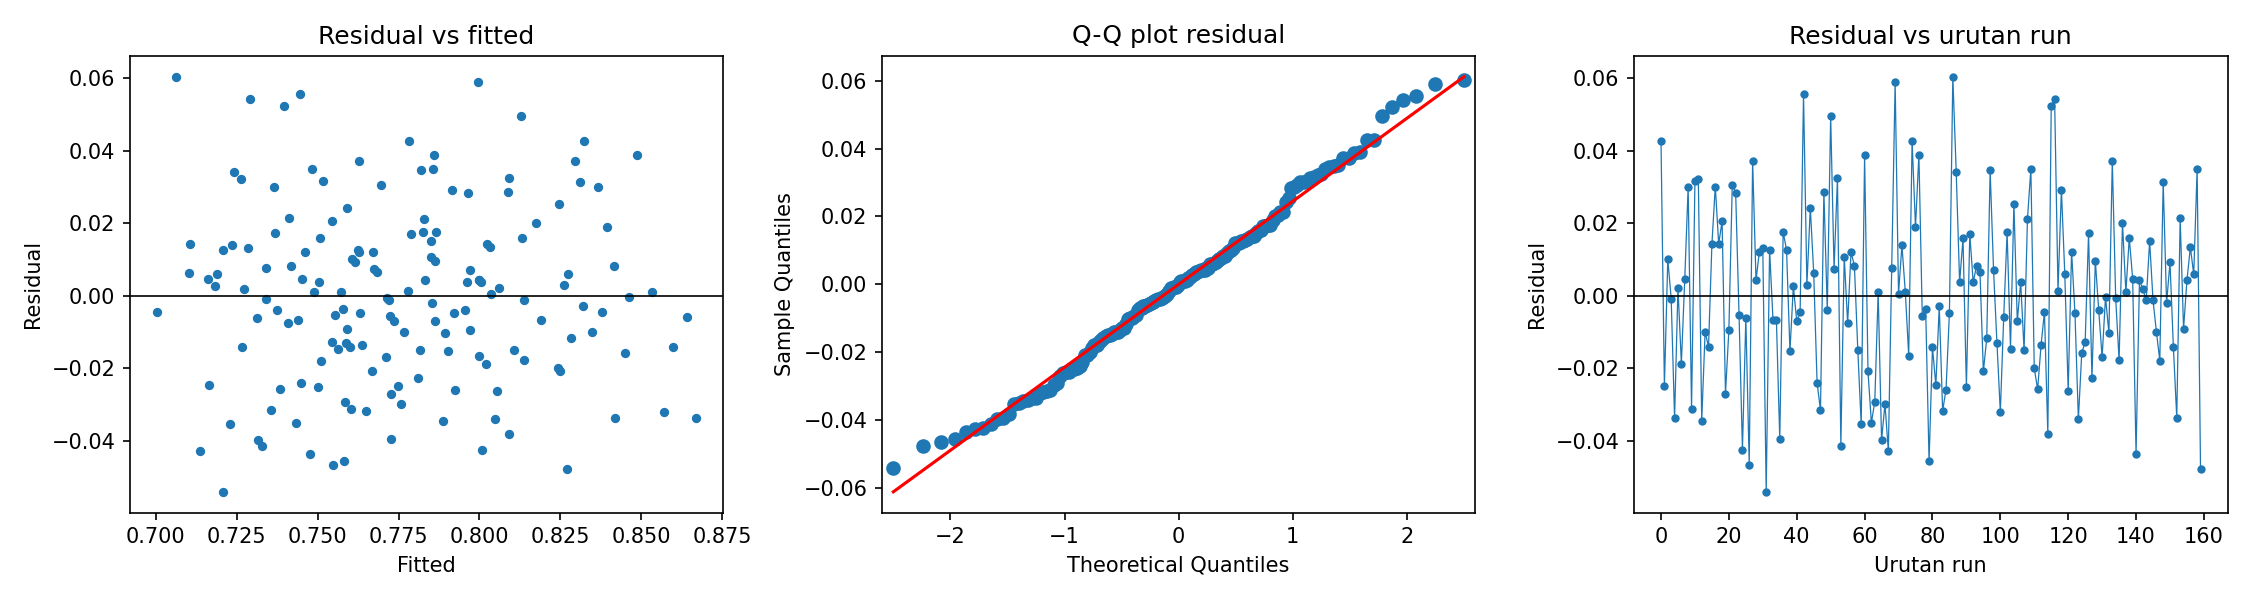

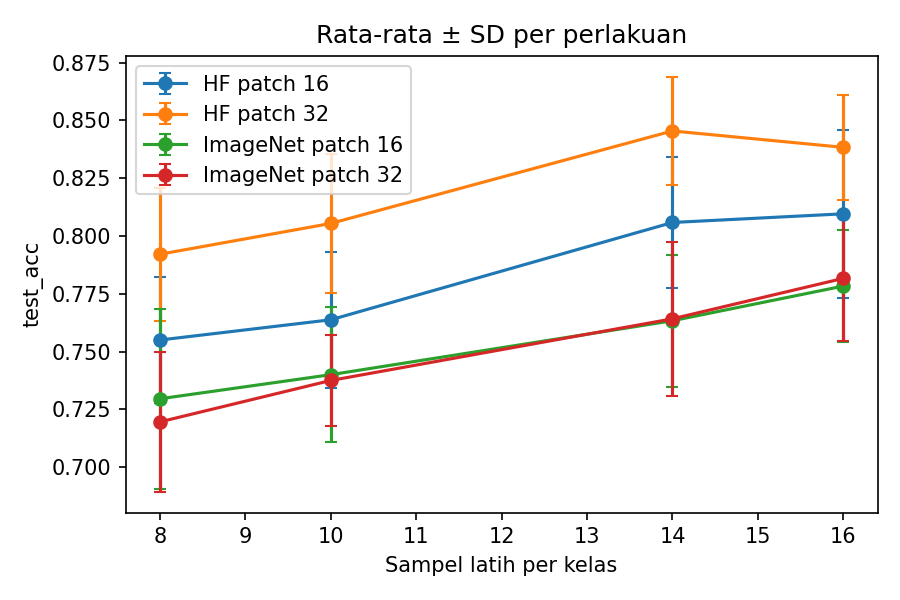

In [6]:
from IPython.display import Image, display
display(Image("/kaggle/working/anova_out/residual_plots.png"))
display(Image("/kaggle/working/anova_out/interaction_plot.png"))